In [1]:
import numpy as np
import pandas as pd
import json

from typing import Annotated, Literal
from tqdm import tqdm
from pydantic import BaseModel
from pydantic.json import pydantic_encoder

from langchain.prompts import ChatPromptTemplate
from langchain_core.output_parsers.json import JsonOutputParser
from langchain_ollama  import ChatOllama, OllamaEmbeddings

from sklearn.model_selection import train_test_split

# == Sources ==
# https://huggingface.co/spaces/Krisseck/IFEval-Leaderboard
# https://huggingface.co/QuantFactory/NeuralDaredevil-8B-abliterated-GGUF/blob/main/README.md
gen = ChatOllama(
    model     = "llama3-8b-abliterated:latest", # this is a custom model I loaded to ollama (best slm on ifeval)
    base_url  = "http://localhost:11434",
    #reasoning = True,
)
emb = OllamaEmbeddings(
    model     = "qwen3:8b",
    base_url  = "http://localhost:11434",
)

class QA(BaseModel):
    """Question/Response to the customer service."""

    question: Annotated[str, "The question asked by the user"]
    response: Annotated[str, "The response from customer support"]

class ModelResponse(BaseModel):
    """Typesafe list of question/responses"""
    
    data: Annotated[list[QA], "List of question/responses"]

Action = Literal[
    "ACTUAL_SEARCH",
    "CORRECTION",
    "DELETE_LOCKED_ACCOUNT",
    "EXPLAIN_FAQ",
    "HUMAN_TAKEOVER",
    "MANUAL_ACTIVATION",
    "REDIRECT",
    "REJECT"
]

template = ChatPromptTemplate.from_template(
    """
    Below are three examples of emails that my customer support
    has received. As I want to train an AI to process and triage
    such emails, I need to create synthetic data. Hence, I want
    you to invent {n} coherent emails (and responses), similar to 
    the examples that have been given to you.

    # Output Format
    I want you to output these emails as an array of json objects
    formatted as such: 
    {{"question": "the user's request email", "response": "the customer support response"}}

    The final output should contain nothing more than the json output
    which must strictly adhere to the following schema: 
    {{"data": [
        {{"question": "1st question", "response": "response to 1st question"}}, 
        {{"question": "2nd question", "response": "response to 2nd question"}}, 
        {{"question": "3rd question", "response": "response to 3rd question"}}, 
        ]
    }}

    # Examples
    {examples}
    """
)

augment = (template | gen.with_structured_output(ModelResponse) )
corpus  = pd.read_parquet("./corpus_clean.parquet")
corpus  = corpus[["question", "response", "action", "embedding"]]
train,test = train_test_split(
    corpus, 
    train_size   = 0.8, 
    stratify     = corpus["action"],
    shuffle      = True,
    random_state = 42,
)


In [2]:
train[["action", "question"]].groupby("action", observed=True).count().sort_values(by="question", ascending=False)

,question
action,
MANUAL_ACTIVATION,97
CORRECTION,38
REDIRECT,31
EXPLAIN_FAQ,27
HUMAN_TAKEOVER,25
ACTUAL_SEARCH,5
REJECT,5
DELETE_LOCKED_ACCOUNT,3


In [3]:
def data_augmentation(
    corpus: pd.DataFrame, 
    action: Action,
    n     : int = 30,
    by    : int = 10,
    nsmpl : int = 3,
) -> pd.DataFrame:
    """Create synthetic data similar to the original."""
    print(f"*** {action:^20} ***")
    # filter the appropriate source dataset
    shard     = corpus[corpus["action"] == action]
    qa        = shard[["question", "response"]]
    synthetic = {
        "question"  : [],
        "response"  : [],
        "action"    : [],
        "embedding" : [],
    }
    for i in tqdm(range((n+1) // by)):
        # build examples list for template
        smpl = qa.sample(nsmpl)
        examples = []
        for i,row in smpl.iterrows():
            examples.append(QA(question=row["question"], response=row["response"]))
        examples = json.dumps(examples, default=pydantic_encoder)
        # create a bunch of synthetic data
        generated = augment.invoke({"examples": examples, "n": by})
        for r in generated.data:
            synthetic["question"].append(r.question)
            synthetic["response"].append(r.response)
            synthetic["action"].append(action)
    
    # generate document embeddings for all synthetic data
    synthetic["embedding"] = list(np.array(emb.embed_documents(synthetic["question"])))
    return pd.DataFrame.from_dict(synthetic)

In [5]:
corr_augm = data_augmentation(
    train, 
    "CORRECTION", 
    n=50,
    by=5,
)
corr_augm.to_parquet("./augment/corr_augm.parquet")

redir_augm = data_augmentation(
    train, 
    "REDIRECT", 
    n=50,
    by=5,
)
redir_augm.to_parquet("./augment/redir_augm.parquet")

faq_augm = data_augmentation(
    train, 
    "EXPLAIN_FAQ", 
    n=60,
    by=5,
)
faq_augm.to_parquet("./augment/faq_augm.parquet")

hum_augm = data_augmentation(
    train, 
    "HUMAN_TAKEOVER", 
    n=60,
    by=5,
)
hum_augm.to_parquet("./augment/hum_augm.parquet")

del_augm = data_augmentation(
    train, 
    "DELETE_LOCKED_ACCOUNT", 
    n=90,
    by=10,
)
del_augm.to_parquet("./augment/del_augm.parquet")

act_augm = data_augmentation(
    train, 
    "ACTUAL_SEARCH", 
    n=90,
    by=10,
)
act_augm.to_parquet("./augment/act_augm.parquet")

rej_augm = data_augmentation(
    train, 
    "REJECT", 
    n=90,
    by=10,
)
rej_augm.to_parquet("./augment/rej_augm.parquet")

augmentations = pd.concat([
    train, 
    corr_augm, 
    redir_augm, 
    faq_augm, 
    hum_augm, 
    del_augm, 
    act_augm, 
    rej_augm,
])

augmentations.to_parquet("train_augment.parquet")
# no actual data augmentation has been done on the test set. 
# This label is only meant to differenciate from other splits I made previously
test.to_parquet("test_augment.parquet") 

***               REJECT ***


100%|█████████████████████████████████████████████| 9/9 [07:56<00:00, 53.00s/it]


In [8]:
len(augmentations)

662

In [11]:
print(augmentations.iloc[9]["question"])

**De  :** rateaum1@gmail.com <rateaum1@gmail.com>  
**Envoyé  :** mercredi 3 juillet 2024 18:15  
**À  :** digita <digita@arch.be>  
**Objet  :** Genealogische bronnen - Andere problemen of vragen



geraak niet meer in de archieven om  
I

* * *

Voornaam : Rateau Magda


[]

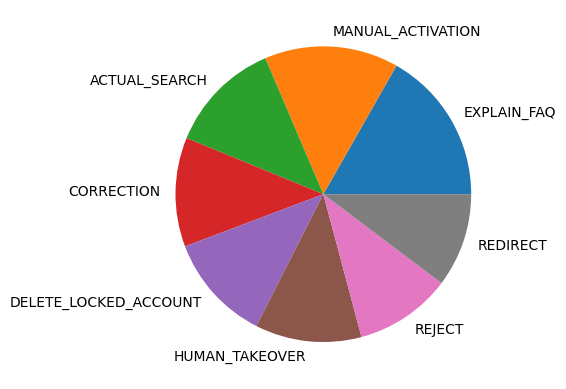

In [21]:
# voilà, on a tellement gonflé le truc que ca semble à peu pres équilibré cette fois
x = augmentations[['question', 'action']].groupby("action", observed=False).count().sort_values(by="question", ascending=False)
ax = x.plot.pie(y="question", legend=None)
ax.set_ylabel('')
ax.plot()

In [1]:
import numpy as np
import pandas as pd

In [3]:
augmentations = pd.read_parquet("train_augment.parquet")
test          = pd.read_parquet("test_augment.parquet")

augmentations["action"] = augmentations["action"].astype("category")
test["action"]          = test["action"].astype("category")

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

X = np.stack(augmentations["embedding"])
Y = np.asarray(augmentations["action"])

softmax = LogisticRegression()

grid = GridSearchCV(
    estimator=softmax,
    param_grid= {
        "C": [29, 30, 31, 32, 33, 34, 45],
        "max_iter": [400, 500, 600, 900],
    },
    cv=3,
    n_jobs=-1,
)
grid.fit(X, Y)

,estimator,LogisticRegression()
,param_grid,"{'C': [29, 30, ...], 'max_iter': [400, 500, ...]}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [5]:
softmax = grid.best_estimator_
grid.best_params_

{'C': 45, 'max_iter': 400}

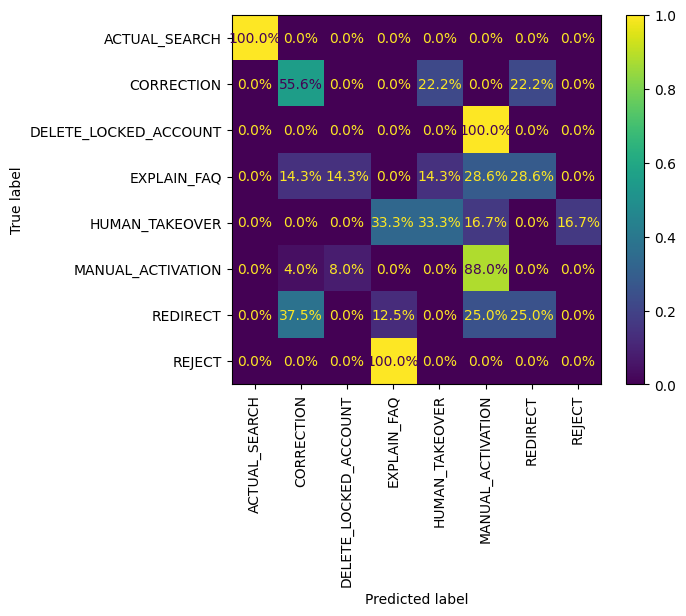

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

X_dev = np.stack(test["embedding"])
Y_dev = np.asarray(test["action"])
Y_pred= softmax.predict(X_dev)

ConfusionMatrixDisplay.from_predictions(Y_dev, Y_pred, normalize='true', values_format="2.1%", xticks_rotation="vertical")

In [23]:
from sklearn.ensemble import RandomForestClassifier


X = np.stack(augmentations["embedding"])
Y = np.asarray(augmentations["action"].astype("category"))

X_dev = np.stack(test["embedding"])
Y_dev = np.asarray(test["action"])

forest = RandomForestClassifier()
forest.fit(X, Y)

Y_pred= forest.predict(X_dev)

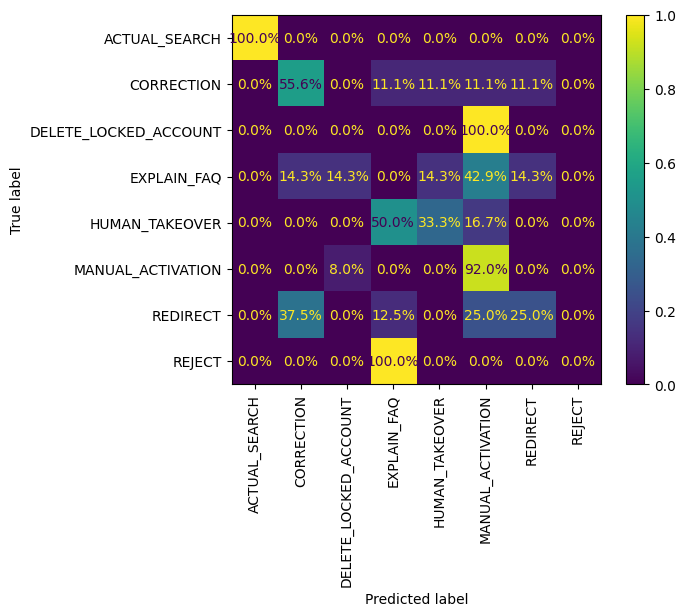

In [24]:
ConfusionMatrixDisplay.from_predictions(Y_dev, Y_pred, normalize='true', values_format="2.1%", xticks_rotation="vertical")

# Conclusion

Les modèles qu'on a jusqu'ici ne sont vraiment pas foufou. Leur performance est assez mauvaise, hormis pour les cas ou 
il faut réellement mener une recherche et les cas ou il faut faire une activation manuelle. (la confusion entre delete_locked_account et manual_activation n'est pas catastrophique et l'un dans l'autre, elle a pas mal de sens.

In [25]:
import joblib


joblib.dump(forest, "../classifier/random_forest.pkl")
joblib.dump(softmax, "../classifier/softmax.pkl")

['../classifier/softmax.pkl']